
# Out-of-sample evaluation of a cluster-momentum strategy
### A walk-forward analysis: train, validation and test

| | |
|---|---|
| **Prepared by** | [Your name] |
| **Context** | [Course, project or audience] |
| **Date** | 28 October 2026 |
| **Evaluation period** | October 2019 to September 2026: 84 months, 7 folds, all after trading costs |
| **Data** | CRSP via WRDS (licensed; raw data are not included here) |
| **Code** | `momentum-rebalancer` repository: `src/momentum_rebalancer/strategy/walkforward.py` |

**Contents:** Summary of findings · About the strategy and data · 1 The idea · 2 Timeline · 3 What was chosen · 4 Train vs validation vs test · 5 Did validation carry over · 6 The out-of-sample record · 7 Summary in numbers · 8 Analysis · 9 What this does and does not tell you · 10 Reproducibility



## Summary of findings

A strategy that groups stocks into peer clusters and buys the strongest recent performers in each was evaluated with a
**walk-forward**: at each step its settings were chosen using only past data, then tested on the following year, which had
played no part in the choice. Seven such tests, joined together, form an honest out-of-sample record.

| After 10 bps trading costs | Walk-forward | Fixed baseline | SPY |
|---|---:|---:|---:|
| Total return | 255.6% | 118.9% | 184.0% |
| Annual return | 19.9% | 11.8% | 16.1% |
| Sharpe (return per unit of risk) | 1.01 | 0.68 | 0.99 |
| Worst drop | -26.7% | -21.8% | -23.9% |
| Volatility (estimated) | about 22% | about 20% | about 18% |

- **Matched the market on a risk-adjusted basis, with more risk.** The walk-forward earned 19.9% a year against
  16.1% for SPY, but the Sharpe ratios are almost the same (1.01 vs 0.99), and it had a deeper worst drop
  (-26.7% vs -23.9%) and higher volatility.
- **Clearly beat the original fixed settings,** which earned 11.8% a year at a Sharpe of 0.68 and trailed SPY. The chosen setting beat them in
  6 of 7 test blocks.
- **Choosing the best-looking setting was not shown to add skill.** The highest validation score (fold 2, Sharpe 2.48) was followed by the only losing
  year (-21%); the lowest (fold 3, Sharpe 0.20) was followed by the largest gain over the baseline (35% against 4%).
- **The lead over SPY opened late,** from around the end of 2023, so it rests largely on the last three test blocks.
- **Costs matter.** The original settings trade about 138% of the portfolio every month; at the 10 basis points assumed here, trading costs
  roughly equal their edge before costs (section 8.5).

*Read as evidence from one seven-year history, not as proof.*



## About the strategy and the data

**Universe.** Companies that were in the S&P 500 at each month-end, using the point-in-time membership list from CRSP, including companies
later delisted, then the 150 most liquid by five-year average dollar volume. All 824 index members in the window have prices, and delisting
returns are part of the data, which removes the main source of survivorship bias.

**Each month-end the strategy:**
1. computes 19 features for every stock: volatility, RSI, MACD, ATR, Bollinger bands, a liquidity rank, returns over 1 to 12 months, and five Fama-French factor betas (every
   feature uses only information available at that month-end);
2. splits the stocks into peer groups (clusters) with K-Means;
3. buys the stocks with the best recent return inside each group, long-only;
4. weights them with Hierarchical Risk Parity (HRP), holds them for one month, and repeats.

**Costs.** 10 basis points per unit traded (an assumption), charged on the actual change in each position, with positions drifting between rebalances.

**The dials the walk-forward chooses:** the momentum window (3, 6 or 12 months), stocks per group (3 to 5) and number of groups (4 to 6): 27 combinations.
**Blocks:** a training block that starts at 48 months and grows, a 12-month validation block, a one-month gap, and a 12-month test block, stepped forward a year at a time.
The **fixed baseline** is the original untuned setting: 3-month momentum, 4 stocks in each of 5 groups (20 names).


## 1. The idea in plain English

The strategy has a few **dials**: how far back to look for momentum (3, 6 or 12 months), how many stocks to
hold per group (3 to 5), and how many groups to split the market into (4 to 6). Together that is 27 combinations.

Nothing is "trained" on prices the way a machine-learning model is. But the dials still have to be set, and the
temptation is to pick whichever combination looks best over **all** the history, then report how well it did over
that same history. That is like writing an exam after seeing the answers: the score looks great and means little.

**Walk-forward** fixes this by replaying history as if you were living through it. At each step you choose the dials
using only the past, then see how they do on the next stretch of time that you have not looked at.

| Block | What it is | Used for |
|---|---|---|
| **Train** | The oldest history | Shown for reference only: how the chosen setting did here. Not used to choose |
| **Validation** | The next 12 months | The "practice exam": all 27 settings are tried here and the best one is kept |
| **Embargo** | A one-month gap | Makes sure the choice cannot touch the test block |
| **Test (out-of-sample)** | The following 12 months | The chosen setting is **frozen** and run here. These months played no part in choosing it |

Then everything slides forward a year and repeats. Each repetition is a **fold**. Joined end to end, the test blocks
form the **only honest performance record**: every number in it was produced by a setting that was picked
*before* it saw those months.

*Two small details.* Months in the tables are **signal months**: the month you make the decision. The return
arrives the following month. And all results are **after trading costs** (10 basis points per trade, an assumption).

In [1]:
import os
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Optional: point this at your results folder if the automatic search below does not find it, e.g.
#   RESULTS_DIR = r"C:\Users\you\Desktop\Personal Modeling Projects\mr-research-data\results"
RESULTS_DIR = None


def find_results_folder() -> Path:
    candidates = []
    if RESULTS_DIR:
        candidates.append(Path(RESULTS_DIR))
    if os.environ.get("MR_RESULTS_DIR"):
        candidates.append(Path(os.environ["MR_RESULTS_DIR"]))
    if os.environ.get("MR_DATA_ROOT"):
        candidates.append(Path(os.environ["MR_DATA_ROOT"]) / "results")
    here = Path.cwd().resolve()
    root = here.parent if here.name == "notebooks" else here
    candidates += [root / "data" / "results", root.parent / "mr-research-data" / "results"]
    for c in candidates:
        if c.exists() and list(c.glob("walkforward_folds_*.csv")):
            return c
    raise FileNotFoundError(
        "No walk-forward results found. Run `mr walkforward --save` first (with the same MR_DATA_ROOT you "
        "want to look at), or set RESULTS_DIR at the top of this cell.\nLooked in:\n  "
        + "\n  ".join(str(c) for c in candidates))


def newest(folder: Path, pattern: str):
    files = sorted(folder.glob(pattern), key=lambda p: p.stat().st_mtime)
    return files[-1] if files else None


folder = find_results_folder()
folds = pd.read_csv(newest(folder, "walkforward_folds_*.csv"), index_col="fold")
oos = pd.read_csv(newest(folder, "walkforward_oos_*.csv"), index_col=0, parse_dates=True)
bt_file = newest(folder, "backtest_*.csv")
spy = None
if bt_file is not None:
    bt = pd.read_csv(bt_file, index_col=0, parse_dates=True)
    if "benchmark" in bt and bt["benchmark"].reindex(oos.index).notna().all():
        spy = bt["benchmark"].reindex(oos.index)

print(f"Results folder : {folder}")
print(f"Folds          : {len(folds)}")
print(f"Out-of-sample  : {len(oos)} months, {oos.index.min():%Y-%m} to {oos.index.max():%Y-%m}")
print(f"SPY comparison : {'available' if spy is not None else 'not available (run `mr backtest --save` to add it)'}")
folds

Results folder : C:\Users\15126\Desktop\Personal Modeling Projects\mr-research-data\results
Folds          : 7
Out-of-sample  : 84 months, 2019-10 to 2026-09
SPY comparison : available


,train,validation,test,chosen_momentum_feature,chosen_top_n_per_cluster,chosen_n_clusters,train_sharpe,val_sharpe,test_sharpe,test_return,baseline_test_sharpe,baseline_test_return
fold,,,,,,,,,,,,
0,2014-08..2018-07,2018-08..2019-07,2019-09..2020-08,return_6m,3,4,0.874980,0.519844,1.121574,0.215433,0.681164,0.134219
1,2014-08..2019-07,2019-08..2020-07,2020-09..2021-08,return_3m,3,4,0.522091,1.652363,1.549835,0.280979,1.241538,0.244559
2,2014-08..2020-07,2020-08..2021-07,2021-09..2022-08,return_3m,3,4,0.769917,2.483541,-1.003392,-0.206221,-0.881093,-0.160190
3,2014-08..2021-07,2021-08..2022-07,2022-09..2023-08,return_6m,3,4,0.988563,0.202283,1.602658,0.352187,0.312119,0.042198
4,2014-08..2022-07,2022-08..2023-07,2023-09..2024-08,return_12m,3,4,0.719157,1.424936,1.954487,0.403329,1.650550,0.247445
5,2014-08..2023-07,2023-08..2024-07,2024-09..2025-08,return_12m,5,4,0.661434,1.584302,0.891149,0.155453,0.703393,0.119052
6,2014-08..2024-07,2024-08..2025-07,2025-09..2026-08,return_12m,5,5,0.755977,1.885912,1.154510,0.312326,1.043622,0.268996


## 2. The timeline: what was used when

Each row is one fold. **Grey** is the training block, **orange** the validation block (where the setting is chosen),
and **green** the test block (never used to choose). The small white gap between orange and green is the one-month embargo.

Things to notice:
- The grey block **grows** with each fold, because every fold knows more history than the last.
- The green blocks never overlap, and none of them sits inside a grey or orange block.
- Read top to bottom, the green blocks together cover the whole out-of-sample period.

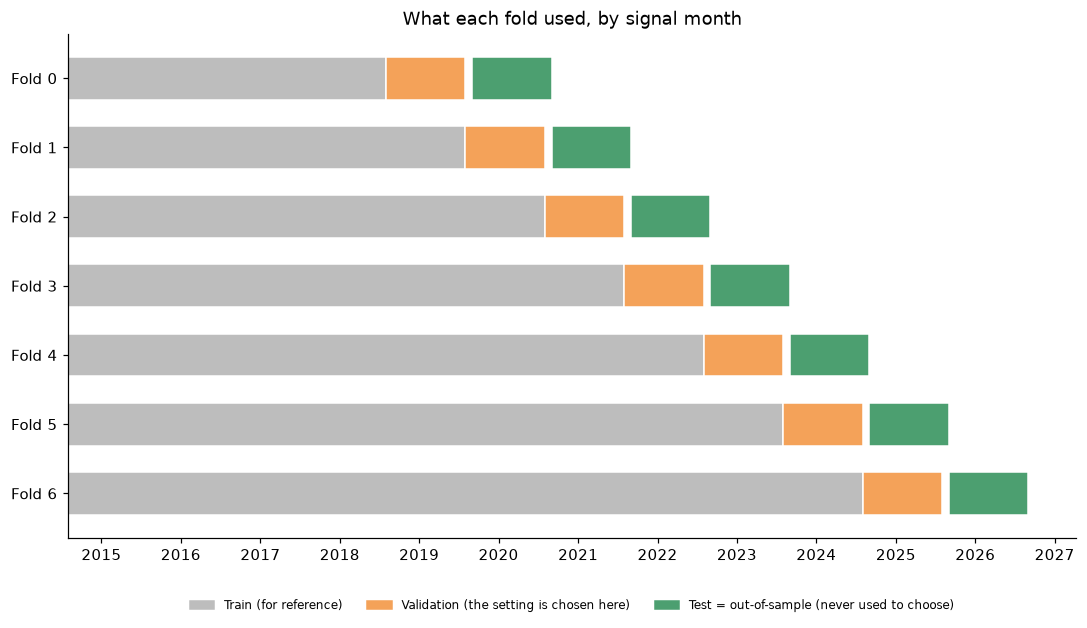

In [2]:
def span(label):
    start, end = label.split("..")
    s, e = pd.Period(start, "M"), pd.Period(end, "M")
    return mdates.date2num(s.to_timestamp()), mdates.date2num(e.to_timestamp(how="end"))

colors = {"train": "#bdbdbd", "validation": "#f4a259", "test": "#4c9f70"}
fig, ax = plt.subplots(figsize=(10, 0.6 * len(folds) + 1.6))
for i, (k, row) in enumerate(folds.iterrows()):
    for block in ("train", "validation", "test"):
        a, b = span(row[block])
        ax.barh(i, b - a, left=a, color=colors[block], edgecolor="white", height=0.62)
ax.set_yticks(range(len(folds)))
ax.set_yticklabels([f"Fold {k}" for k in folds.index])
ax.invert_yaxis()
ax.xaxis_date()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(handles=[Patch(color=colors["train"], label="Train (for reference)"),
                   Patch(color=colors["validation"], label="Validation (the setting is chosen here)"),
                   Patch(color=colors["test"], label="Test = out-of-sample (never used to choose)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False, fontsize=8)
ax.set_title("What each fold used, by signal month")
plt.tight_layout()
plt.show()

## 3. What the process picked in each fold

For every fold, all 27 settings were tried on the validation block and the best one (highest Sharpe, after costs) was
kept. A setting that gets picked again and again is more believable than one that changes every time.

Watch for settings sitting at the **edge** of what was offered (the smallest or largest value in the grid): that hints that
the best answer may lie outside the options we gave it.

In [3]:
chosen = folds[["test", "chosen_momentum_feature", "chosen_top_n_per_cluster", "chosen_n_clusters"]].rename(columns={
    "test": "Test block (signal months)", "chosen_momentum_feature": "Momentum window",
    "chosen_top_n_per_cluster": "Stocks per group", "chosen_n_clusters": "Groups"})
display(chosen)

counts = (folds.groupby(["chosen_momentum_feature", "chosen_top_n_per_cluster", "chosen_n_clusters"]).size()
          .sort_values(ascending=False).rename("folds picked").reset_index())
print("\nHow often each setting was chosen:")
display(counts)

try:
    from momentum_rebalancer import config
    grid = config.load_walk_forward()["grid"]
    for key, col in [("top_n_per_cluster", "chosen_top_n_per_cluster"), ("n_clusters", "chosen_n_clusters")]:
        lo, hi = min(grid[key]), max(grid[key])
        n_edge = int(folds[col].isin([lo, hi]).sum())
        print(f"{key}: options were {grid[key]}; the lowest or highest option was picked in {n_edge} of {len(folds)} folds")
except Exception:
    pass

,Test block (signal months),Momentum window,Stocks per group,Groups
fold,,,,
0,2019-09..2020-08,return_6m,3,4
1,2020-09..2021-08,return_3m,3,4
2,2021-09..2022-08,return_3m,3,4
3,2022-09..2023-08,return_6m,3,4
4,2023-09..2024-08,return_12m,3,4
5,2024-09..2025-08,return_12m,5,4
6,2025-09..2026-08,return_12m,5,5



How often each setting was chosen:


,chosen_momentum_feature,chosen_top_n_per_cluster,chosen_n_clusters,folds picked
0,return_6m,3,4,2
1,return_3m,3,4,2
2,return_12m,3,4,1
3,return_12m,5,5,1
4,return_12m,5,4,1


top_n_per_cluster: options were [3, 4, 5]; the lowest or highest option was picked in 7 of 7 folds
n_clusters: options were [4, 5, 6]; the lowest or highest option was picked in 6 of 7 folds


## 4. Train vs validation vs test performance

**Sharpe** is return per unit of risk (annualised, risk-free rate taken as 0). Higher is better, and negative means the
setting lost money.

How to read the bars for each fold:
- **Grey (train):** how the chosen setting did on the oldest data. For reference.
- **Orange (validation):** how it did on the exam it was **picked** for. This is flattered, because it was chosen *for being
  best here*. Always expect it to look good.
- **Green (test):** how it did afterwards, on months it had never seen. **This is the honest number.**
- **Black diamond:** the original untuned settings (the fixed baseline) over the same test months, for comparison.

Green bars well below the orange bars mean the picking process was partly chasing luck.

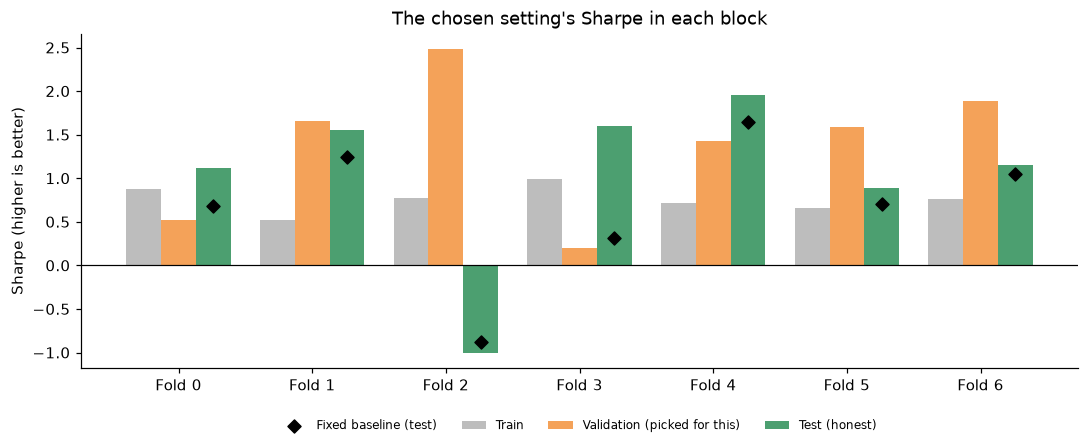

Average Sharpe of the chosen setting:  validation 1.39   ->   test 1.04
The chosen setting beat the fixed baseline in 6 of 7 test blocks


In [4]:
x = np.arange(len(folds)); w = 0.26
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bar(x - w, folds["train_sharpe"], w, color=colors["train"], label="Train")
ax.bar(x, folds["val_sharpe"], w, color=colors["validation"], label="Validation (picked for this)")
ax.bar(x + w, folds["test_sharpe"], w, color=colors["test"], label="Test (honest)")
ax.scatter(x + w, folds["baseline_test_sharpe"], marker="D", color="black", zorder=5, label="Fixed baseline (test)")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([f"Fold {k}" for k in folds.index])
ax.set_ylabel("Sharpe (higher is better)")
ax.set_title("The chosen setting's Sharpe in each block")
ax.legend(frameon=False, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

print(f"Average Sharpe of the chosen setting:  validation {folds['val_sharpe'].mean():.2f}   ->   test {folds['test_sharpe'].mean():.2f}")
print(f"The chosen setting beat the fixed baseline in {(folds['test_sharpe'] > folds['baseline_test_sharpe']).sum()} of {len(folds)} test blocks")

## 5. Did a good validation result carry over to the test?

Each dot is one fold. Left to right is how well the chosen setting did on validation (where it was picked); bottom to top
is how well it did on the test afterwards.

- If picking the best validation setting **works**, the dots slope upward: better validation, better test.
- If the dots form a **cloud** or slope downward, the validation winner was mostly lucky, and picking it told you little.
- Dots **below the dashed line** did worse on the test than on validation, which is the normal, expected direction.

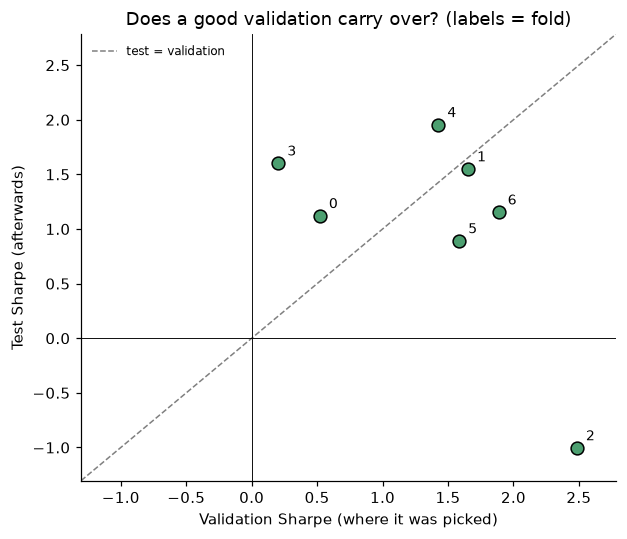

In [5]:
fig, ax = plt.subplots(figsize=(5.8, 5))
ax.scatter(folds["val_sharpe"], folds["test_sharpe"], s=70, color=colors["test"], edgecolor="black", zorder=3)
for k, r in folds.iterrows():
    ax.annotate(f"{k}", (r["val_sharpe"], r["test_sharpe"]), xytext=(6, 5), textcoords="offset points", fontsize=9)
lims = [min(folds[["val_sharpe", "test_sharpe"]].min()) - 0.3, max(folds[["val_sharpe", "test_sharpe"]].max()) + 0.3]
ax.plot(lims, lims, "--", color="grey", lw=1, label="test = validation")
ax.axhline(0, color="black", lw=0.6); ax.axvline(0, color="black", lw=0.6)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Validation Sharpe (where it was picked)"); ax.set_ylabel("Test Sharpe (afterwards)")
ax.set_title("Does a good validation carry over? (labels = fold)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 6. The out-of-sample record

Now the test blocks are joined end to end. This is what you would have earned by following the process live: at each fold,
use the setting chosen from the past, then hold it through the next year. Returns are **after costs**.

The shaded bands are the individual test blocks. The lines show growth of 1 unit of money. The **fixed baseline** is the
original untuned settings over the same months. If SPY is shown, it is a simple buy-and-hold comparison.

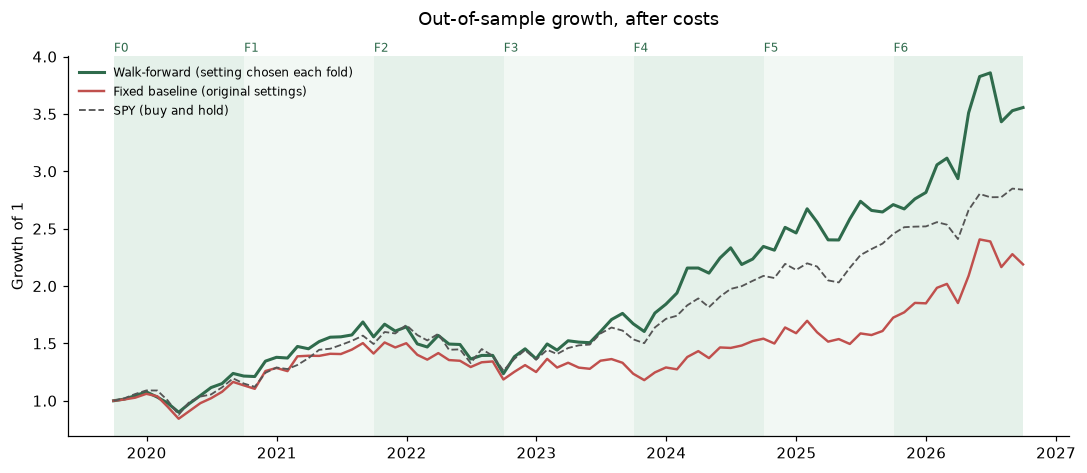

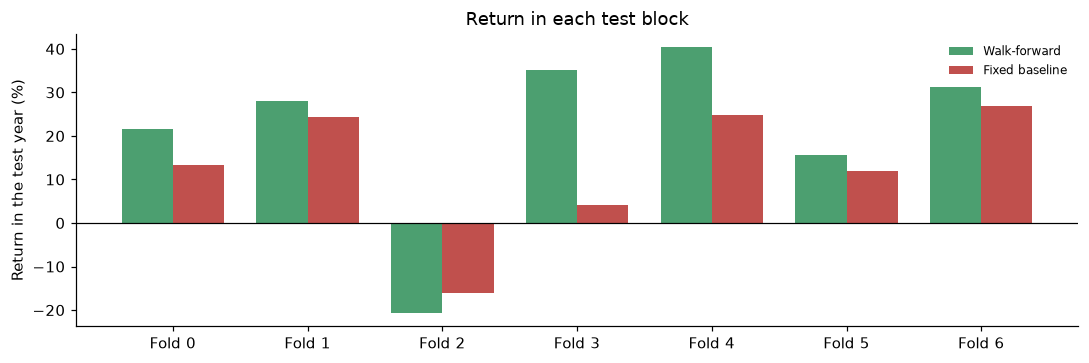

In [6]:
def growth(r):
    start = r.index[0] - pd.offsets.MonthEnd(1)
    return pd.concat([pd.Series([1.0], index=[start]), (1 + r).cumprod()])

fig, ax = plt.subplots(figsize=(10, 4.4))
for i, (k, row) in enumerate(folds.iterrows()):
    a, b = [pd.Period(p, "M") for p in row["test"].split("..")]
    ax.axvspan((a + 1).to_timestamp(), (b + 1).to_timestamp(how="end"), color="#4c9f70", alpha=0.07 if i % 2 else 0.14, lw=0)
    ax.text((a + 1).to_timestamp(), 1.01, f"F{k}", transform=ax.get_xaxis_transform(), fontsize=8, color="#2f6b4c")
ax.plot(growth(oos["walk_forward"]), color="#2f6b4c", lw=2, label="Walk-forward (setting chosen each fold)")
ax.plot(growth(oos["fixed_baseline"]), color="#c0504d", lw=1.6, label="Fixed baseline (original settings)")
if spy is not None:
    ax.plot(growth(spy), color="#555555", lw=1.2, ls="--", label="SPY (buy and hold)")
ax.set_ylabel("Growth of 1"); ax.set_title("Out-of-sample growth, after costs", pad=20)
ax.legend(frameon=False, fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.4))
x = np.arange(len(folds)); w = 0.38
ax.bar(x - w / 2, folds["test_return"] * 100, w, color="#4c9f70", label="Walk-forward")
ax.bar(x + w / 2, folds["baseline_test_return"] * 100, w, color="#c0504d", label="Fixed baseline")
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([f"Fold {k}" for k in folds.index]); ax.set_ylabel("Return in the test year (%)")
ax.set_title("Return in each test block"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 7. The summary in numbers

In [7]:
def annual(r): return (1 + r).prod() ** (12 / len(r)) - 1
def sharpe(r): return r.mean() / r.std() * np.sqrt(12)
def worst_drop(r):
    w = (1 + r).cumprod()
    return (w / w.cummax() - 1).min()

series = {"Walk-forward": oos["walk_forward"], "Fixed baseline": oos["fixed_baseline"]}
if spy is not None:
    series["SPY"] = spy
summary = pd.DataFrame({name: {"Total return": (1 + r).prod() - 1, "Annual return": annual(r),
                               "Sharpe": sharpe(r), "Worst drop": worst_drop(r)} for name, r in series.items()})
shown = summary.copy().astype(object)
for row in ("Total return", "Annual return", "Worst drop"):
    shown.loc[row] = [f"{v:.1%}" for v in summary.loc[row]]
shown.loc["Sharpe"] = [f"{v:.2f}" for v in summary.loc["Sharpe"]]
print(f"{len(oos)} out-of-sample months, {oos.index.min():%Y-%m} to {oos.index.max():%Y-%m}, after costs\n")
display(shown)

84 out-of-sample months, 2019-10 to 2026-09, after costs



,Walk-forward,Fixed baseline,SPY
Total return,255.6%,118.9%,184.0%
Annual return,19.9%,11.8%,16.1%
Sharpe,1.01,0.68,0.99
Worst drop,-26.7%,-21.8%,-23.9%



## 8. Analysis of the results

### 8.1 Matched the market on risk-adjusted terms; beat the original settings
Over the 84 out-of-sample months the walk-forward returned **19.9% a year** against **16.1%** for SPY. Its Sharpe ratio is almost
identical to SPY's (**1.01 vs 0.99**), its worst drop was deeper (**-26.7% vs -23.9%**) and its volatility was higher (about 22% against
18%, estimated from the table's return and Sharpe). In plain terms, the extra return came with extra risk; it was not a better risk-adjusted outcome than holding SPY.

Against the original untuned settings the picture is clearer. Those earned 11.8% a year at a Sharpe of 0.68, trailing SPY on both counts, and the
walk-forward beat them in 6 of 7 test blocks.

### 8.2 When the gains arrived
In the growth chart (section 6) the walk-forward stays close to SPY through most of 2023, falling behind in the 2022 sell-off, and pulls ahead from late 2023.
Splitting the seven blocks, the first four (October 2019 to September 2023) compound to **67.1%** and the last three (October 2023 to September 2026) to **112.8%**.
The final block also contains a sharp rise to a peak in mid-2026 followed by a pullback of roughly a tenth, so the end value depends on where the record stops.
With seven blocks the data cannot say whether the late lead reflects a lasting property of the method or a favourable stretch of the market.

### 8.3 Did choosing the best-looking setting help?
There is evidence both ways. In its favour, the chosen setting beat the baseline in 6 of 7 blocks, and the average Sharpe fell from 1.39 (validation) to
1.04 (test), the ordinary optimism of a score picked for being the best, while staying well above the baseline's 0.68.

Against it, the validation ranking did not predict the test ranking:
- **Fold 2** had the highest validation Sharpe (2.48) and was the only losing test block (Sharpe -1.00, -21%, against -16% for the baseline).
- **Fold 3** had the *lowest* validation Sharpe (0.20) and produced the largest gain over the baseline (35% against 4%, a lead of 31 percentage points).
- Across the seven folds, validation and test Sharpe moved in opposite directions on average (correlation -0.6), though seven points are too few to call that a pattern.

The fair reading is that the *procedure* produced a decent record, not that a high validation score identifies the best setting.

### 8.4 What the process chose
Five different settings were chosen in seven folds, so there is no single stable "best". The smallest option offered for stocks per group (3) was picked in five folds, and the smallest for number of groups (4)
in six, which suggests the best choice may lie outside the options tried. The momentum window lengthened over time (6m → 3m → 3m → 6m → 12m → 12m → 12m). The portfolio held 12 stocks in the first five folds and
20 and 25 in the last two, so the late lead did not depend on a tiny portfolio.

### 8.5 Costs
The strategy trades heavily: with the original settings about 138% of the portfolio's value changes hands every month (buys plus sells). The full-period backtest of those settings
(September 2014 to September 2026, 145 months, against SPY's 13.6% a year) at two cost levels shows how much that matters:

| Cost per unit traded | Net return | Sharpe | Return beyond beta × SPY (CAPM alpha) |
|---|---:|---:|---:|
| 5 bps | 13.4% | 0.83 | +0.9% |
| 10 bps (used throughout this notebook) | 12.5% | 0.78 | 0.0% |

For these settings, at 10 bps the cost of trading roughly equals the edge they had before costs. The walk-forward itself was run only at 10 bps; re-running it at other cost levels is a natural next step.

### 8.6 Bottom line
Judged out of sample, the strategy delivered market-like risk-adjusted returns (Sharpe 1.01 against SPY's 0.99) and clearly improved on its original fixed settings, at the price of higher risk and heavy trading.
The results do not show that choosing settings by validation performance adds skill, and they come from a single seven-year history. Sensible next steps are to reduce turnover, re-test at 5 and 20 basis points,
widen the grid once (labelled exploratory, since these test blocks have now been seen), and gather more history.



## 9. What this does and does not tell you

**It does tell you** how a disciplined process (choose using only the past, then test on unseen months) would have done, which is far more honest than choosing
the best setting on all the history.

**It does not tell you:**
- **What happens next.** It is one 12-year history split into seven folds.
- **That the choices outside the grid are sound.** Decisions such as the universe size or the type of features were made by people who had already seen the history, and walk-forward cannot undo that.
- **That the costs are right.** Ten basis points per trade is an assumption; the answer is sensitive to it (section 8.5).
- **That the results will repeat with different data.** Research here uses CRSP; a live system would use a different, more current source, so its picks would differ somewhat.
- **That the test blocks are still unseen.** Every time they are inspected and something is then changed, they stop being out-of-sample. Treat any re-tuned result as exploratory.



## 10. Reproducibility, data and environment

**To reproduce** (from the project folder, with the CRSP settings active):
```
set MR_PRICE_SOURCE=crsp
set MR_DATA_ROOT=<a research data folder outside the repository>
mr build-features --force
mr cluster --force
mr walkforward --save
mr backtest --save
```
Then open `notebooks/01_walk_forward_explained.ipynb` and choose **Run All** to regenerate every chart from the saved results.

| What | Where |
|---|---|
| Settings: folds, grid, costs | `configs/walk_forward.yaml`, `configs/strategy.yaml`, `configs/crsp.yaml` |
| Walk-forward code | `src/momentum_rebalancer/strategy/walkforward.py` |
| Simulation behind every number | `src/momentum_rebalancer/strategy/simulate.py` |
| Written methodology | `docs/VALIDATION.md`, `docs/DATA_SOURCES.md` |

**Environment (from the installation log):** Python 3.12.5, pandas 2.2.3, NumPy 2.2.6, `momentum-rebalancer` 0.2.0. Results were generated on 28 October 2026.
The project has an automated test suite (`pytest`), including checks that the features use no future information and that the walk-forward's choices never depend on its test blocks.

**Data.** CRSP data are licensed through WRDS and are not redistributed; this notebook contains only aggregated results. Fama-French factor returns come from the Kenneth French Data Library.
